In [209]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset # Ajout de Subset

In [210]:
#size of batch 
train_size = 10

#number of epochs for pre-train
num_epochs = 10
#number of sample we take from 50000 images
samples = 200 
#number of epochs for final train with the inpainting image
num_epochs_fine = 100

device = torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
height = 128 #pixel h
width = 128 #pixel w

In [211]:
# Load dataset
transform = T.Compose([
        T.Resize((height, width)), 
        T.ToTensor(),
        T.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)) 
    ])

trainset = torchvision.datasets.CIFAR10(
    root='./data_cifar_pretrain_full', 
    train=True, 
    download=True, 
    transform=transform
)

indices = torch.randperm(len(trainset))[:samples]
pretrain_subset = Subset(trainset, indices)

# Create dataloaders
trainloader = DataLoader(
    pretrain_subset, 
    batch_size=train_size, 
    shuffle=True, )




In [212]:
#Autoencoder

class Autoencoder(nn.Module):
    def __init__(self, input_channels=3, output_channels = 3):
        super().__init__()
        
        self.Encoder_1 = nn.Sequential( 
            nn.Conv2d(input_channels, 64, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),
            
        )
        
        self.pool1 = nn.MaxPool2d(2,2)


        self.Encoder_2 = nn.Sequential( 
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(), 
            nn.Conv2d(128, 128, 3, padding=1),
            nn.ReLU()
        )

        self.pool2 = nn.MaxPool2d(2,2)

        self.Encoder_3 = nn.Sequential( 
            nn.Conv2d(128, 256, 3, padding=1),
            nn.ReLU(), 
            nn.Conv2d(256, 256, 3, padding=1),
            nn.ReLU()
        )

        self.up_1 = nn.ConvTranspose2d(256, 128, 2, 2)

        self.decoder_1 = nn.Sequential(
            nn.Conv2d(256, 128, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.ReLU()
        )

        self.up_2 = nn.ConvTranspose2d(128, 64, 2, 2)

        self.decoder_2 = nn.Sequential(
            nn.Conv2d(128, 64, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU()
        )

        self.output = nn.Conv2d(64,output_channels,1)
        self.function_activation_output = nn.Tanh()

    def forward(self, x):
        
        x1 = self.Encoder_1(x)
        x2 = self. pool1(x1)

        x3 = self.Encoder_2(x2)
        x4 = self.pool2(x3)

        x5=self.Encoder_3(x4)
        

        x6 = self.up_1(x5)
        x6 = torch.cat((x3,x6),dim=1) 
        x6 = self.decoder_1(x6)

        x7 = self.up_2(x6)
        x7 = torch.cat((x1,x7),dim=1)
        x7 = self.decoder_2(x7)

        output = self.output(x7)
        output = self.function_activation_output(output)

        return output

In [213]:
def imshow(img,title = ""):
    img = img / 2 + 0.5     # unnormalize to show images correctly
    npimg = img.cpu().detach().numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    if title : plt.title(title)

In [214]:
def mask_batch(images_batch, min_hole_scale=0.2, max_hole_scale=0.4):
    masked_images_list = []
    
    
    _, _, img_h, img_w = images_batch.shape
    
    for img in images_batch: 
        # Create the mask ( 0.0 = hole or 1.0 either)
        mask = torch.ones_like(img)
        
        #the size of holes 
        hole_h = int(np.random.uniform(min_hole_scale, max_hole_scale) * img_h)
        hole_w = int(np.random.uniform(min_hole_scale, max_hole_scale) * img_w)
        
        # position of holes
        offset_y = np.random.randint(0, img_h - hole_h + 1)
        offset_x = np.random.randint(0, img_w - hole_w + 1)
        
        # create the mask with the position and size of hole 
        mask[:, offset_y : offset_y + hole_h, offset_x : offset_x + hole_w] = 0.0
        
        # apply the mask on the img
        masked_img = img * mask
        
        masked_images_list.append(masked_img)
        
    return torch.stack(masked_images_list)

In [215]:
# pre-train for all pictures

model = Autoencoder().to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)


valtrain = []

for epoch_nr in range(num_epochs):

    print("Epoch {}:".format(epoch_nr))

    # Train model
    running_loss = 0.0

    for i,(batch_data,_) in enumerate(trainloader) : 
   
        #we take one picture    
        input = mask_batch(
            batch_data, 
            min_hole_scale=0.25, 
            max_hole_scale=0.5
        )
        
        batch_data = input.to(device)

        
        target_data = batch_data

        optimizer.zero_grad()
        output = model(batch_data)
        loss = criterion(output,target_data)
        loss.backward()
        optimizer.step() #update the weight 
        running_loss += loss.item()
        if (i + 1) % (len(trainloader) // 2 if len(trainloader) > 1 else 1) == 0:
                 print(f"  Pre-train : [{epoch_nr+1}/{num_epochs}], Batch [{i+1}/{len(trainloader)}], Val_loss: {loss.item():.4f}")
    epoch_loss = running_loss/len(trainloader)  
    valtrain.append(epoch_loss)




Epoch 0:
  Pre-train : [1/10], Batch [10/20], Val_loss: 0.0478
  Pre-train : [1/10], Batch [20/20], Val_loss: 0.0245
Epoch 1:
  Pre-train : [2/10], Batch [10/20], Val_loss: 0.0190
  Pre-train : [2/10], Batch [20/20], Val_loss: 0.0090
Epoch 2:
  Pre-train : [3/10], Batch [10/20], Val_loss: 0.0116
  Pre-train : [3/10], Batch [20/20], Val_loss: 0.0076
Epoch 3:
  Pre-train : [4/10], Batch [10/20], Val_loss: 0.0055
  Pre-train : [4/10], Batch [20/20], Val_loss: 0.0053
Epoch 4:
  Pre-train : [5/10], Batch [10/20], Val_loss: 0.0058
  Pre-train : [5/10], Batch [20/20], Val_loss: 0.0060
Epoch 5:
  Pre-train : [6/10], Batch [10/20], Val_loss: 0.0057
  Pre-train : [6/10], Batch [20/20], Val_loss: 0.0047
Epoch 6:
  Pre-train : [7/10], Batch [10/20], Val_loss: 0.0038
  Pre-train : [7/10], Batch [20/20], Val_loss: 0.0032
Epoch 7:
  Pre-train : [8/10], Batch [10/20], Val_loss: 0.0035
  Pre-train : [8/10], Batch [20/20], Val_loss: 0.0017
Epoch 8:
  Pre-train : [9/10], Batch [10/20], Val_loss: 0.0020
 

In [216]:
index = 15 #choice one picture from 200 pictures
image, _ = trainset[index]
image_batch  = image.unsqueeze(0) #selection of a fixed picture 

In [217]:
#train for image with mask
batch_loss = []
for epoch_nr in range(num_epochs_fine) : 
    single_batch = mask_batch(
            image_batch, 
            min_hole_scale=0.25, 
            max_hole_scale=0.5
        )
    input_data = single_batch.to(device)
    target_data = image_batch.to(device)
    optimizer.zero_grad()
    output = model(input_data)
    loss = criterion(output, target_data)
    loss.backward()
    optimizer.step()
    current_loss = loss.item()
    batch_loss.append(current_loss)
    if (epoch_nr + 1) % (num_epochs_fine // 5 if num_epochs_fine >=5 else 1) == 0 or epoch_nr == num_epochs_fine - 1:
          print(f"  specific train for an image [{epoch_nr+1}/{num_epochs_fine}], Val_loss: {current_loss:.4f}")
else:
    batch_loss = []




  specific train for an image [20/100], Val_loss: 0.0149
  specific train for an image [40/100], Val_loss: 0.0325
  specific train for an image [60/100], Val_loss: 0.0194
  specific train for an image [80/100], Val_loss: 0.0103
  specific train for an image [100/100], Val_loss: 0.0077


In [218]:
final_batch = mask_batch(image_batch)
final_image = final_batch[0].cpu()
with torch.no_grad() : 
    final_input =  final_batch.to(device)
    final_reconstructed = model(final_input)
    final_reconstructed_display = final_reconstructed[0].cpu()


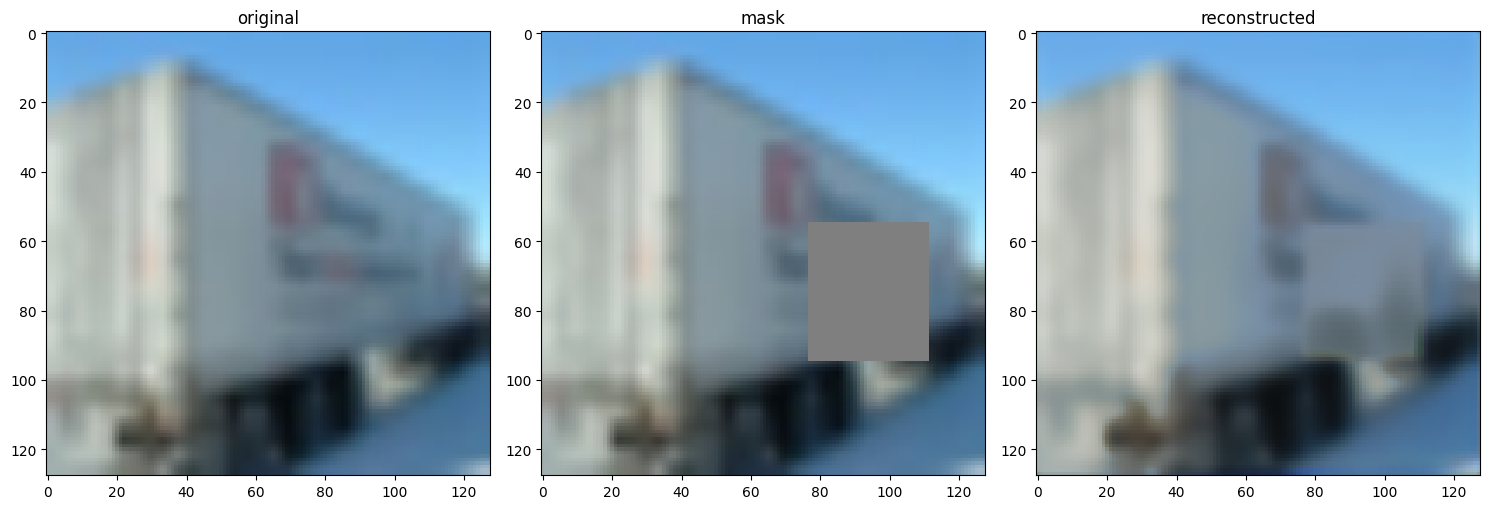

In [219]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
imshow(image.cpu(), title= "original")
plt.subplot(1, 3, 2)
imshow(final_image, title="mask")
plt.subplot(1, 3, 3)
imshow(final_reconstructed_display,title ="reconstructed")
plt.tight_layout()
plt.show()
